# Biological insight: what the predicted uncertainty is reading

Reads **only** the parquets written by `snake/scripts/bio/bio_axis_precompute.py`. No loop over
predictions here: this notebook loads and plots.

Prerequisite (cluster login node, repo root):

```bash
DRYRUN=1 bash snake/scripts/bio/launch_bio_axis_precompute.sh   # check which run dirs matched
bash snake/scripts/bio/launch_bio_axis_precompute.sh            # 3 CPU jobs, ~15 min
```

**Claim under test.** The predicted uncertainty reads the expression regime (a property of the
gene, the same in every patient); the error depends on whether that cohort's biology happens to be
written in the morphology (a property of the cohort). That mismatch is why the uncertainty is
redundant with the mean.

**Rules held throughout.**
- `sigma` is raw, never multiplied by `(1+mu)`: that Jacobian is a function of the mean and would
  manufacture the coupling being measured.
- Never pooled across cohorts (the tissue-level sigma-error relation has opposite signs on TuPro
  and TLS).
- Unit of replication is the **donor** (7 / 6 / 8), never the spot.
- Every figure has a printed twin of its numbers.


## 0. Config

In [14]:
import sys, json
from pathlib import Path

PROJ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').is_dir())
sys.path.append(str(PROJ))   # parent dir of src (the notebooks are not pip-installed here)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

RUN_ID   = 'pr_classic3'
RESULTS  = PROJ / 'results'
MODEL    = 'heteroscedastic'      # the only head whose sigma varies per (spot, gene)
LAMBDA   = 'lambda_0.0'           # beta-NLL exponent 0 = the proper NLL
RADIUS   = 'r75'
DATASETS = ['10x_TuPro', 'TLS', 'LUNG_CANCER']
DATASET_LABELS = {'10x_TuPro': 'TuPro (melanoma)', 'TLS': 'TLS (kidney/lung)',
                  'LUNG_CANCER': 'NSCLC'}

# DISTINCT filename per run, so re-running one notebook can never overwrite another run's figure.
FIG_DIR = PROJ / 'results' / '_analysis' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save_fig(fig, slug):
    for ext in ('pdf', 'png'):
        fig.savefig(FIG_DIR / f'fig_{slug}_{RUN_ID}.{ext}', dpi=300, bbox_inches='tight')
    print('wrote:', f'fig_{slug}_{RUN_ID}.pdf')


# Canonical tissue -> color map, keyed on the label
# so a tissue keeps one color everywhere. Both vocabularies live in one dict; they do not collide.
TISSUE_COLORS = {
    'Tumor': '#D62728', 'Blood and necrosis': '#F08A24', 'Stroma': '#D9C7A3',
    'Normal lymphoid tissue': '#3FA34D', 'Pigment': '#26415F',
    'TUM': '#D62728', 'NOR': '#3FA34D', 'INFL': '#F08A24', 'LN': '#D9C7A3', 'TLS': '#3B6BC4',
}
DS_COLORS = {'10x_TuPro': '#7B3294', 'TLS': '#1B7837', 'LUNG_CANCER': '#B35806'}


# scipy shims: the repo uses the older API (.correlation), so index the tuple, which works on every
# version. binomtest replaced binom_test in scipy 1.7.
def spear(a, b):
    return float(stats.spearmanr(a, b)[0])


def signtest_p(k, n):
    '''Two-sided sign-test p. Floor at n donors: 2 * 0.5**n.'''
    if hasattr(stats, 'binomtest'):
        return float(stats.binomtest(int(k), int(n), 0.5).pvalue)
    return float(stats.binom_test(int(k), int(n), 0.5))


def bio_dir(ds):
    p = RESULTS / ds / RUN_ID / f'_{ds}_hvg_top3000' / RADIUS / MODEL
    return (p / LAMBDA / 'bio_axis') if (p / LAMBDA).is_dir() else (p / 'bio_axis')


def load(ds):
    d = bio_dir(ds)
    if not (d / 'per_spot.parquet').exists():
        print(f'  MISSING  {ds}: {d}')
        return None
    out = {k: pd.read_parquet(d / f'{k}.parquet')
           for k in ('per_gene', 'per_spot', 'variance_shares')}
    out['summary'] = json.loads((d / 'summary.json').read_text())
    out['dir'] = d
    return out


D = {ds: load(ds) for ds in DATASETS}
D = {k: v for k, v in D.items() if v is not None}
print(f'\nloaded: {list(D)}')


loaded: ['10x_TuPro', 'TLS', 'LUNG_CANCER']


## 1. Inventory

What each cohort actually contributes: donors, scales, annotation columns present. `LUNG_CANCER`
most likely carries no per-spot tissue label, in which case it enters only the gene sections (2, 3,
4) and drops out of the tissue sections (5, 6).

In [15]:
rows = []
for ds, d in D.items():
    s = d['summary']
    homog = ','.join(c.replace('homog_', '') for c in s['homogeneity_cols'])
    rows.append(dict(dataset=ds, donors=len(s['donors']), spots=s['n_spots'], genes=s['n_genes'],
                     mu_scale=s['mu_scale'], sigma_scale=s['sigma_scale'],
                     labels=','.join(s['label_cols']) or 'NONE',
                     homogeneity=homog or 'NONE', genes_sd0=s['n_gene_columns_with_zero_sd']))
print(pd.DataFrame(rows).set_index('dataset').to_string())

print('\nobs columns joined, per cohort:')
for ds, d in D.items():
    print(f"  {ds:12s} {d['summary']['extra_obs_cols']}")

print('\ngenes_sd0 = number of gene columns whose sigma does not vary across spots.')
print('For heteroscedastic it should be ~0; for homoscedastic it would equal n_genes (sanity check).')

             donors  spots  genes mu_scale  sigma_scale                                    labels                               homogeneity  genes_sd0
dataset                                                                                                                                               
10x_TuPro         7  77338   3000    CP10k  log1p-CP10k                              ground_truth                              ground_truth          0
TLS               6  19437   3000    CP10k  log1p-CP10k  ground_truth,ground_truth_knn_spatial_15  ground_truth,ground_truth_knn_spatial_15          0
LUNG_CANCER       8  68659   3000    CP10k  log1p-CP10k                                      NONE                                      NONE          0

obs columns joined, per cohort:
  10x_TuPro    ['label', 'label_conf', 'blur_vars', 'foreground_ratios', 'n_counts', 'size_factor_total_over_1e4', 'size_factor_median_ratios', 'sample_id', 'Whitespace', 'Normal lymphoid tissue', 'Pigment', 'Str

## 2. The uncertainty is a property of the gene, the error is not

Two-way decomposition of `log(sigma)` over each donor's (spots x genes) matrix: the share of the
variance carried by a **gene main effect** (one constant per gene), by a **spot main effect**, and
by the **interaction** (the only part depending on both, hence the only place a prediction-specific
uncertainty can live).

**The readable quantity is the GAP** between the gene share of `log(sigma)` and that of
`log|error|`, never the level of the first: if the error were also 0.9 gene-level, the model would
be right rather than redundant.

In [16]:
sh = pd.concat([d['variance_shares'].assign(dataset=ds) for ds, d in D.items()], ignore_index=True)

print('PER DONOR (the unit of replication)')
print(sh.pivot_table(index=['dataset', 'test_donor'], columns='quantity',
                     values=['share_gene', 'share_spot', 'share_interaction', 'sd_interaction'])
        .round(4).to_string())

print('\nMEAN OVER DONORS')
print(sh.groupby(['dataset', 'quantity'])
        .agg(share_gene_mean=('share_gene', 'mean'), share_gene_sd=('share_gene', 'std'),
             share_spot_mean=('share_spot', 'mean'), share_int_mean=('share_interaction', 'mean'),
             sd_int_mean=('sd_interaction', 'mean'), n=('share_gene', 'size'))
        .round(4).to_string())

gap = (sh.pivot_table(index=['dataset', 'test_donor'], columns='quantity', values='share_gene')
         .assign(gap=lambda t: t['log_sigma'] - t['log_abs_err']))
print('\nGAP  share_gene(log sigma) - share_gene(log |error|), per donor:')
print(gap.round(4).to_string())
for ds, g in gap.groupby(level=0):
    v = g['gap'].to_numpy()
    ci = stats.t.interval(0.95, len(v) - 1, loc=v.mean(), scale=stats.sem(v)) if len(v) > 1 else (np.nan, np.nan)
    print(f'  {ds:12s} mean gap {v.mean():+.4f}  95% CI [{ci[0]:+.4f}, {ci[1]:+.4f}]  '
          f'({int((v > 0).sum())}/{len(v)} donors > 0)')

PER DONOR (the unit of replication)
                       sd_interaction            share_gene           share_interaction            share_spot          
quantity                  log_abs_err log_sigma log_abs_err log_sigma       log_abs_err log_sigma log_abs_err log_sigma
dataset     test_donor                                                                                                 
10x_TuPro   MACEGEJ            1.0030    0.2202      0.7278    0.9157            0.2661    0.0519      0.0062    0.0324
            MAHEFOG            0.9386    0.1777      0.7681    0.9270            0.2288    0.0321      0.0031    0.0409
            MAJOFIJ            0.9577    0.1823      0.7387    0.9111            0.2493    0.0362      0.0121    0.0527
            MAKYGIW            0.8480    0.1432      0.8167    0.9358            0.1791    0.0212      0.0042    0.0431
            MANOFYB            0.9844    0.1927      0.7265    0.8742            0.2677    0.0410      0.0058    0.0849
    

wrote: fig_bio_variance_shares_pr_classic3.pdf


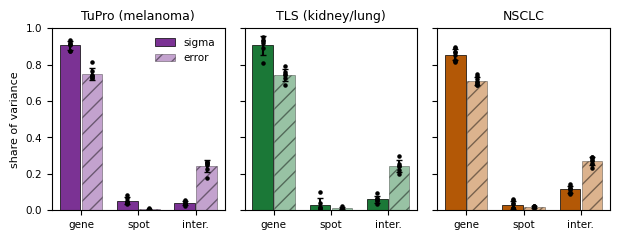


CAPTION: Two-way variance decomposition of the predicted log-uncertainty (solid) and of the log absolute error (hatched), per cohort. Bars are the mean over held-out donors, whiskers the between-donor standard deviation, black dots the individual donors.


In [17]:
# SIZED FOR A PORTRAIT PAGE: drawn at roughly its printed width (~6.3 in textwidth), NOT larger --
# a wide figure shrunk by \\includegraphics[width=\\textwidth] has its fonts shrunk by the same
# factor and becomes unreadable. No suptitle: it would only duplicate the LaTeX caption.
parts = ['share_gene', 'share_spot', 'share_interaction']
fig, axes = plt.subplots(1, len(D), figsize=(6.3, 2.5), sharey=True)
axes = np.atleast_1d(axes)

for ax, (ds, d) in zip(axes, D.items()):
    s = d['variance_shares']
    x = np.arange(len(parts))
    for i, (q, lab) in enumerate([('log_sigma', 'sigma'), ('log_abs_err', 'error')]):
        sub = s[s['quantity'] == q]
        ax.bar(x + (i - 0.5) * 0.38, [sub[p].mean() for p in parts], 0.36,
               yerr=[sub[p].std(ddof=1) for p in parts], capsize=2.5,
               hatch=None if q == 'log_sigma' else '//',
               color=DS_COLORS.get(ds, 'gray'), alpha=1.0 if q == 'log_sigma' else 0.45,
               edgecolor='k', linewidth=0.5, label=lab)
        for p_i, p in enumerate(parts):        # the K donor points, always drawn
            ax.scatter(np.full(len(sub), p_i + (i - 0.5) * 0.38), sub[p], s=5, color='k', zorder=3)
    ax.set_xticks(x)
    ax.set_xticklabels(['gene', 'spot', 'inter.'], fontsize=7.5)
    ax.tick_params(labelsize=7.5)
    ax.set_title(DATASET_LABELS.get(ds, ds), fontsize=9)
    ax.set_ylim(0, 1)
axes[0].set_ylabel('share of variance', fontsize=8)
axes[0].legend(fontsize=7.5, frameon=False, loc='upper right')
fig.tight_layout()
save_fig(fig, 'bio_variance_shares')
plt.show()

print('\nCAPTION: Two-way variance decomposition of the predicted log-uncertainty (solid) and of'
      ' the log absolute error (hatched), per cohort. Bars are the mean over held-out donors,'
      ' whiskers the between-donor standard deviation, black dots the individual donors.')

## 3. Which genes, by name

The qualitative deliverable. `pearson` comes from the run's own `atoms.parquet` (hence the headline
convention): averaged per (donor, slide, gene), then over that donor's slides, then over donors.

In [18]:
GENE = {}
for ds, d in D.items():
    g = d['per_gene']
    cols = [c for c in ('pearson', 'mean_log_sigma', 'mean_sigma_raw', 'mean_mu', 'mean_y',
                        'pct_zero', 'mean_abs_err') if c in g.columns]
    GENE[ds] = g.groupby('gene', observed=True)[cols].mean()      # mean over donors
    print(f'{ds:12s} {GENE[ds].shape[0]} genes, columns {cols}')

N = 20
SHOW = ['pearson', 'mean_y', 'pct_zero', 'mean_sigma_raw']
for ds, g in GENE.items():
    if 'pearson' not in g.columns:
        print(f'\n{ds}: no pearson column, skipped')
        continue
    gg = g.dropna(subset=['pearson']).sort_values('pearson', ascending=False)
    lab = DATASET_LABELS.get(ds, ds)
    print(f'\n===== {lab}: {N} BEST predicted genes =====')
    print(gg.head(N)[SHOW].round(4).to_string())
    print(f'\n===== {lab}: {N} WORST predicted genes =====')
    print(gg.tail(N)[SHOW].round(4).to_string())
    print(f'\n===== {lab}: {N} HIGHEST uncertainty genes (raw sigma) =====')
    print(g.sort_values('mean_sigma_raw', ascending=False).head(N)[SHOW].round(4).to_string())
    print(f'\n===== {lab}: {N} LOWEST uncertainty genes =====')
    print(g.sort_values('mean_sigma_raw').head(N)[SHOW].round(4).to_string())

10x_TuPro    3000 genes, columns ['pearson', 'mean_log_sigma', 'mean_sigma_raw', 'mean_mu', 'mean_y', 'pct_zero', 'mean_abs_err']
TLS          3000 genes, columns ['pearson', 'mean_log_sigma', 'mean_sigma_raw', 'mean_mu', 'mean_y', 'pct_zero', 'mean_abs_err']
LUNG_CANCER  3000 genes, columns ['pearson', 'mean_log_sigma', 'mean_sigma_raw', 'mean_mu', 'mean_y', 'pct_zero', 'mean_abs_err']

===== TuPro (melanoma): 20 BEST predicted genes =====
         pearson   mean_y  pct_zero  mean_sigma_raw
gene                                               
MLANA     0.6378   7.0120    0.1177          0.4453
TMSB4X    0.6311  48.5004    0.0040          0.4113
SOX10     0.6263   4.9753    0.1300          0.4277
ERBB3     0.6244   4.5333    0.1211          0.4218
COL1A1    0.6233  13.0854    0.1143          0.6735
COL3A1    0.6147  11.7512    0.1047          0.6306
CD63      0.6077  35.9655    0.0253          0.3590
COL6A2    0.6049   2.8521    0.1814          0.4842
MYO10     0.6047   5.6436    0.1055

Spearman per cohort, over genes:
  10x_TuPro    n= 3000 | sigma~expression +0.958 | accuracy~expression +0.575 | accuracy~sigma +0.583 | accuracy~zero-fraction -0.509
  TLS          n= 3000 | sigma~expression +0.976 | accuracy~expression +0.678 | accuracy~sigma +0.635 | accuracy~zero-fraction -0.671
  LUNG_CANCER  n= 3000 | sigma~expression +0.986 | accuracy~expression +0.828 | accuracy~sigma +0.818 | accuracy~zero-fraction -0.852
wrote: fig_bio_gene_sigma_vs_expression_pr_classic3.pdf


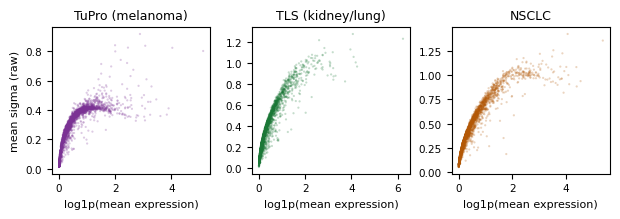


CAPTION: Per-gene predicted uncertainty against the gene mean expression, one point per gene, averaged over held-out donors. The uncertainty is left on its own raw scale; no Jacobian of the mean is applied.


In [19]:
# The confound to state before any biological reading: sigma follows expression, so a gene set
# enriched among high-sigma genes may be nothing more than a gene set of highly expressed genes.
print('Spearman per cohort, over genes:')
for ds, g in GENE.items():
    gg = g.dropna()
    sig, expr, zer = gg['mean_sigma_raw'], gg['mean_y'], gg['pct_zero']
    acc = gg['pearson'] if 'pearson' in gg.columns else None
    r1 = spear(sig, expr)
    r2 = spear(acc, expr) if acc is not None else np.nan
    r3 = spear(acc, sig) if acc is not None else np.nan
    r4 = spear(acc, zer) if acc is not None else np.nan
    print(f'  {ds:12s} n={len(gg):5d} | sigma~expression {r1:+.3f} | accuracy~expression {r2:+.3f}'
          f' | accuracy~sigma {r3:+.3f} | accuracy~zero-fraction {r4:+.3f}')

fig, axes = plt.subplots(1, len(GENE), figsize=(6.3, 2.3))
axes = np.atleast_1d(axes)
for ax, (ds, g) in zip(axes, GENE.items()):
    gg = g.dropna()
    ax.scatter(np.log1p(gg['mean_y']), gg['mean_sigma_raw'], s=2.5, alpha=0.25,
               color=DS_COLORS.get(ds, 'gray'), edgecolors='none')
    ax.set_xlabel('log1p(mean expression)', fontsize=8)
    ax.tick_params(labelsize=7.5)
    ax.set_title(DATASET_LABELS.get(ds, ds), fontsize=9)
axes[0].set_ylabel('mean sigma (raw)', fontsize=8)
fig.tight_layout()
save_fig(fig, 'bio_gene_sigma_vs_expression')
plt.show()

print('\nCAPTION: Per-gene predicted uncertainty against the gene mean expression, one point per'
      ' gene, averaged over held-out donors. The uncertainty is left on its own raw scale; no'
      ' Jacobian of the mean is applied.')

## 4. Does the gene ranking travel between cohorts?

If `sigma` re-encodes a gene's marginal variance, its ranking must replicate from one cohort to the
next, because expression variance is itself a conserved gene trait. Accuracy depends on whether
THIS cohort's biology is morphologically visible, so it should travel less well.

**Mandatory correction.** A raw cross-cohort correlation conflates "it does not travel" with "the
estimate is noisy". Split-half reliability (odd against even donors, within each cohort) gives the
attainable ceiling; both the raw and the disattenuated `rho / sqrt(rel_A * rel_B)` are reported.

SPLIT-HALF RELIABILITY (the ceiling any cross-cohort correlation can reach):
                              10x_TuPro    TLS  LUNG_CANCER
uncertainty (mean_log_sigma)      0.971  0.977        0.989
accuracy (pearson)                0.728  0.358        0.898

CROSS-COHORT TRANSFER
                   pair                     quantity  n_shared_genes  rho_raw  ceiling  rho_disattenuated
        10x_TuPro / TLS uncertainty (mean_log_sigma)             775    0.803    0.974              0.825
        10x_TuPro / TLS           accuracy (pearson)             775    0.363    0.510              0.712
10x_TuPro / LUNG_CANCER uncertainty (mean_log_sigma)             876    0.660    0.980              0.674
10x_TuPro / LUNG_CANCER           accuracy (pearson)             876    0.397    0.808              0.491
      TLS / LUNG_CANCER uncertainty (mean_log_sigma)             703    0.814    0.983              0.828
      TLS / LUNG_CANCER           accuracy (pearson)             703    0.548    0.5

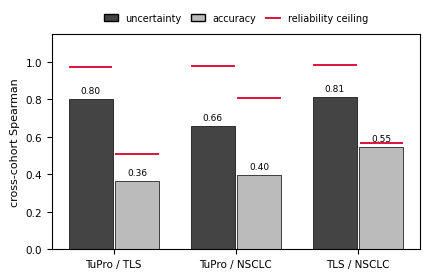


CAPTION: Cross-cohort Spearman correlation of the per-gene ranking, for the predicted uncertainty (dark) and for the prediction accuracy (light), over the genes shared by both panels. Red rules mark the split-half reliability ceiling, the highest correlation attainable given the noise in each cohort own per-gene estimate; a bar must be read against that rule and not against 1.0.


In [20]:
QUANT = {'uncertainty (mean_log_sigma)': 'mean_log_sigma', 'accuracy (pearson)': 'pearson'}


def split_half_reliability(per_gene, col):
    '''Spearman between the odd-donor and even-donor halves, on the same quantity.'''
    donors = sorted(per_gene['test_donor'].unique())
    if len(donors) < 4 or col not in per_gene.columns:
        return np.nan
    a, b = donors[0::2], donors[1::2]
    ga = per_gene[per_gene['test_donor'].isin(a)].groupby('gene', observed=True)[col].mean()
    gb = per_gene[per_gene['test_donor'].isin(b)].groupby('gene', observed=True)[col].mean()
    j = pd.concat([ga, gb], axis=1, keys=['a', 'b']).dropna()
    return spear(j['a'], j['b'])


rel = {ds: {lab: split_half_reliability(d['per_gene'], c) for lab, c in QUANT.items()}
       for ds, d in D.items()}
print('SPLIT-HALF RELIABILITY (the ceiling any cross-cohort correlation can reach):')
print(pd.DataFrame(rel).round(3).to_string())

rows = []
for i, a in enumerate(D):
    for b in list(D)[i + 1:]:
        shared = GENE[a].index.intersection(GENE[b].index)
        for lab, c in QUANT.items():
            if c not in GENE[a].columns or c not in GENE[b].columns:
                continue
            j = pd.concat([GENE[a].loc[shared, c], GENE[b].loc[shared, c]],
                          axis=1, keys=['a', 'b']).dropna()
            raw = spear(j['a'], j['b'])
            lo = min(rel[a][lab], rel[b][lab])
            ceiling = np.sqrt(rel[a][lab] * rel[b][lab]) if lo > 0 else np.nan
            rows.append(dict(pair=f'{a} / {b}', quantity=lab, n_shared_genes=len(j),
                             rho_raw=raw, ceiling=ceiling,
                             rho_disattenuated=raw / ceiling if ceiling else np.nan))
tr = pd.DataFrame(rows)
print('\nCROSS-COHORT TRANSFER')
print(tr.round(3).to_string(index=False) if not tr.empty else '  nothing computable')

SHORT = {'10x_TuPro': 'TuPro', 'TLS': 'TLS', 'LUNG_CANCER': 'NSCLC'}

print('\nHOW TO READ THIS')
print('  rho_raw            observed Spearman between the two cohorts per-gene rankings.')
print('  ceiling            sqrt(rel_A * rel_B), the highest rho that could be observed given')
print('                     how noisy each cohort own estimate is. A raw rho must never be read')
print('                     against 1.0, only against this.')
print('  rho_disattenuated  rho_raw / ceiling, i.e. the share of the attainable signal actually')
print('                     transferred. ~1 means it transfers as well as the data allow.')
print()
for _, r in tr.iterrows():
    print(f"  {r['pair']:26s} {r['quantity']:28s} rho {r['rho_raw']:+.3f} of a ceiling of "
          f"{r['ceiling']:.3f}  ->  {100 * r['rho_disattenuated']:5.1f}% of the attainable signal")

for pair in tr['pair'].unique():
    sub = tr[tr['pair'] == pair].set_index('quantity')
    u = sub.loc['uncertainty (mean_log_sigma)', 'rho_disattenuated']
    a = sub.loc['accuracy (pearson)', 'rho_disattenuated']
    verdict = ('uncertainty transfers BETTER than accuracy' if u > a + 0.05 else
               'accuracy transfers BETTER than uncertainty' if a > u + 0.05 else
               'the two transfer comparably')
    print(f'  {SHORT.get(pair.split(" / ")[0], pair):>6s} vs {SHORT.get(pair.split(" / ")[1], ""):<6s} '
          f'disattenuated {u:.2f} (uncertainty) vs {a:.2f} (accuracy): {verdict}')

if not tr.empty:
    from matplotlib.lines import Line2D
    from matplotlib.patches import Patch

    prs = list(tr['pair'].unique())
    labels = [' / '.join(SHORT.get(q, q) for q in pair.split(' / ')) for pair in prs]
    x = np.arange(len(prs))
    fig, ax = plt.subplots(figsize=(4.4, 2.9))
    BAR_COLORS = ['#444444', '#BBBBBB']
    for i, lab in enumerate(QUANT):
        sub = tr[tr['quantity'] == lab].set_index('pair').reindex(prs)
        xi = x + (i - 0.5) * 0.38
        ax.bar(xi, sub['rho_raw'], 0.36, color=BAR_COLORS[i], edgecolor='k', linewidth=0.5)
        for xx, v, c in zip(xi, sub['rho_raw'], sub['ceiling']):
            if np.isfinite(v):
                ax.text(xx, v + 0.02, f'{v:.2f}', ha='center', va='bottom', fontsize=6.5)
            if np.isfinite(c):
                ax.plot([xx - 0.17, xx + 0.17], [c, c], color='crimson', lw=1.4, zorder=4)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=8)
    ax.tick_params(labelsize=7.5)
    ax.set_ylabel('cross-cohort Spearman', fontsize=8)
    ax.set_ylim(0, 1.15)
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    handles = [Patch(facecolor=BAR_COLORS[0], edgecolor='k', label='uncertainty'),
               Patch(facecolor=BAR_COLORS[1], edgecolor='k', label='accuracy'),
               Line2D([0], [0], color='crimson', lw=1.4, label='reliability ceiling')]
    ax.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, 1.01), ncol=3,
              frameon=False, fontsize=7, handlelength=1.4, columnspacing=1.0)
    fig.tight_layout()
    save_fig(fig, 'bio_gene_transfer')
    plt.show()
    print('\nCAPTION: Cross-cohort Spearman correlation of the per-gene ranking, for the predicted'
          ' uncertainty (dark) and for the prediction accuracy (light), over the genes shared by'
          ' both panels. Red rules mark the split-half reliability ceiling, the highest correlation'
          ' attainable given the noise in each cohort own per-gene estimate; a bar must be read'
          ' against that rule and not against 1.0.')

## 5. Where in the tissue?

Two readings, in this order.

1. **Descriptive** (no test): mean per (slide, tissue) then per donor, for `sigma`, `|error|` and
   the predicted mean. The direction is known in advance from the descriptive tissue-level work
   on these cohorts, so re-testing it here would be circular.
2. **Confirmatory**: once `mu` is known, does the compartment add anything to `sigma`? Isotonic
   regression of `sigma_z` on `mu_z` **within each slide**, then the compartment contrast of the
   residual, sign-tested over donors.

Label rule: TuPro uses raw `ground_truth` (Pigment dropped, 18 spots). TLS uses raw `ground_truth`
restricted to genuinely annotated spots as the primary view, and `ground_truth_knn_spatial_15` as a
secondary always flagged as imputed. Never the `expr` / `emb` imputations (the model target and the
model input respectively).

In [21]:
MIN_SPOTS = 30                                   # per (slide, tissue)
DROP = {'PIGMENT', 'UNASSIGNED', 'NAN', 'NONE', 'NA', 'N/A', '', '<NA>', 'MIXED', 'WHITESPACE'}


def tissue_table(per_spot, label_col):
    '''Slide-aware mean per (donor, tissue): (slide, tissue) first, then over that donor slides.'''
    df = per_spot.copy()
    df['tissue'] = df[label_col].astype(str)
    df = df[~df['tissue'].str.upper().isin(DROP)]
    by_slide = (df.groupby(['test_donor', 'slide', 'tissue'], observed=True)
                  .agg(sigma=('sigma_mean_raw', 'mean'), sigma_z=('sigma_z', 'mean'),
                       err=('err_mean_raw', 'mean'), err_z=('err_z', 'mean'),
                       mu=('mu_mean', 'mean'), mu_z=('mu_z', 'mean'),
                       n=('sigma_mean_raw', 'size')).reset_index())
    by_slide = by_slide[by_slide['n'] >= MIN_SPOTS]
    return (by_slide.groupby(['test_donor', 'tissue'], observed=True)
                    .mean(numeric_only=True).reset_index())


TIS = {}
for ds, d in D.items():
    cols = d['summary']['label_cols']
    if not cols:
        print(f'{ds}: no tissue label, cohort excluded from sections 5 and 6')
        continue
    n_tot = len(d['per_spot'])
    for c in cols:
        t = tissue_table(d['per_spot'], c)
        if t.empty:
            continue
        TIS[(ds, 'genuine' if c == 'ground_truth' else 'imputed')] = t
        n_tis, n_don = t['tissue'].nunique(), t['test_donor'].nunique()
        if c == 'ground_truth':
            n_drop = int(d['per_spot'][c].astype(str).str.upper().isin(DROP).sum())
            print(f'{ds:12s} [{c}] {n_drop:,}/{n_tot:,} spots dropped '
                  f'({100 * n_drop / n_tot:.1f}%), {n_tis} tissues, {n_don} donors')
        else:
            print(f'{ds:12s} [{c}] IMPUTED, {n_tis} tissues, {n_don} donors')

for key, t in TIS.items():
    print(f'\n===== {key[0]} ({key[1]}): per-tissue mean over donors =====')
    print(t.groupby('tissue')[['sigma', 'sigma_z', 'err', 'err_z', 'mu', 'mu_z']]
           .agg(['mean', 'std']).round(4).to_string())
    mm = t.groupby('tissue')[['sigma', 'err', 'mu']].mean()
    if len(mm) >= 3:
        print(f'  Spearman(sigma, |err|) over the {len(mm)} tissues = '
              f'{spear(mm["sigma"], mm["err"]):+.3f}')
        print(f'  Spearman(sigma, mu)    over the {len(mm)} tissues = '
              f'{spear(mm["sigma"], mm["mu"]):+.3f}')
    print('  WARNING: n here is the number of TISSUES, not donors. No interval. Descriptive only.')

10x_TuPro    [ground_truth] 18/77,338 spots dropped (0.0%), 4 tissues, 7 donors
TLS          [ground_truth] 10,110/19,437 spots dropped (52.0%), 5 tissues, 6 donors
TLS          [ground_truth_knn_spatial_15] IMPUTED, 5 tissues, 6 donors
LUNG_CANCER: no tissue label, cohort excluded from sections 5 and 6

===== 10x_TuPro (genuine): per-tissue mean over donors =====
                         sigma         sigma_z             err           err_z              mu            mu_z        
                          mean     std    mean     std    mean     std    mean     std    mean     std    mean     std
tissue                                                                                                                
Blood and necrosis      0.3106  0.0439  0.4079  0.5841  0.9799  0.1360  0.1024  0.0585  1.0080  0.0606  0.1033  0.1280
Normal lymphoid tissue  0.3614  0.0669  0.9147  0.5769  1.1280  0.2513  0.1173  0.1115  0.9518  0.0789 -0.0875  0.1732
Stroma                  0.3593  0.0330

wrote: fig_bio_tissue_sigma_pr_classic3.pdf


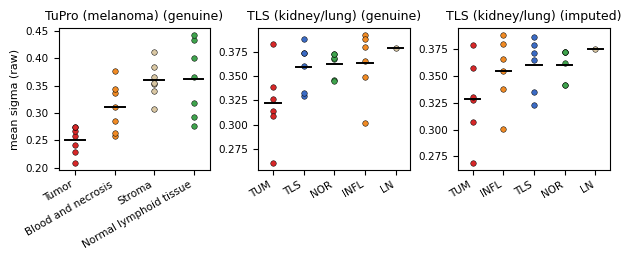


CAPTION: Predicted uncertainty by histological compartment. One point per held-out donor, obtained as the mean per (slide, tissue) then averaged over that donor slides; the black rule is the donor mean. Panels marked imputed use the spatially k-nearest imputed annotation and are not the primary view.


In [22]:
keys = list(TIS)
if keys:
    fig, axes = plt.subplots(1, len(keys), figsize=(6.3, 2.7), squeeze=False)
    for ax, key in zip(axes[0], keys):
        t = TIS[key]
        order = t.groupby('tissue')['sigma'].mean().sort_values().index.tolist()
        for i, tis in enumerate(order):
            s = t[t['tissue'] == tis]
            ax.scatter(np.full(len(s), i), s['sigma'], s=16, color=TISSUE_COLORS.get(tis, 'gray'),
                       edgecolors='k', linewidths=0.35, zorder=3)
            ax.plot([i - 0.25, i + 0.25], [s['sigma'].mean()] * 2, color='k', lw=1.4, zorder=4)
        ax.set_xticks(range(len(order)))
        ax.set_xticklabels(order, rotation=30, ha='right', fontsize=7)
        ax.tick_params(labelsize=7.5)
        ax.set_title(f'{DATASET_LABELS.get(key[0], key[0])} ({key[1]})', fontsize=9)
    axes[0][0].set_ylabel('mean sigma (raw)', fontsize=8)
    fig.tight_layout()
    save_fig(fig, 'bio_tissue_sigma')
    plt.show()
    print('\nCAPTION: Predicted uncertainty by histological compartment. One point per held-out'
          ' donor, obtained as the mean per (slide, tissue) then averaged over that donor slides;'
          ' the black rule is the donor mean. Panels marked imputed use the spatially k-nearest'
          ' imputed annotation and are not the primary view.')

In [23]:
# --- The confirmatory test: does the compartment add to sigma once mu is known? ---
from sklearn.isotonic import IsotonicRegression


def residualized(per_spot, ycol='sigma_z', xcol='mu_z'):
    '''Remove the monotone part of y explained by x, WITHIN each slide.

    Isotonic rather than linear: sigma(mu) has no reason to be linear, and a misspecified form
    would leave mu in the residual, which would make the test complacent.
    '''
    out = np.full(len(per_spot), np.nan)
    for s, idx in per_spot.groupby('slide', observed=True).indices.items():
        x, y = per_spot[xcol].to_numpy()[idx], per_spot[ycol].to_numpy()[idx]
        ok = np.isfinite(x) & np.isfinite(y)
        if ok.sum() < 50:
            continue
        ir = IsotonicRegression(out_of_bounds='clip').fit(x[ok], y[ok])
        out[idx[ok]] = y[ok] - ir.predict(x[ok])
    return out


IMMUNE = {'Normal lymphoid tissue', 'TLS', 'INFL', 'LN'}
TUMOR = {'Tumor', 'TUM'}
res_rows = []
for ds, d in D.items():
    if not d['summary']['label_cols']:
        continue
    ps = d['per_spot'].copy()
    ps['sigma_resid'] = residualized(ps, 'sigma_z', 'mu_z')
    ps['err_resid'] = residualized(ps, 'err_z', 'mu_z')
    for c in d['summary']['label_cols']:
        lab = 'genuine' if c == 'ground_truth' else 'imputed'
        df = ps.copy()
        df['tissue'] = df[c].astype(str)
        df = df[~df['tissue'].str.upper().isin(DROP)]
        by = (df.groupby(['test_donor', 'slide', 'tissue'], observed=True)
                .agg(sigma_resid=('sigma_resid', 'mean'), err_resid=('err_resid', 'mean'),
                     sigma_z=('sigma_z', 'mean'), err_z=('err_z', 'mean'),
                     n=('sigma_z', 'size')).reset_index())
        by = by[by['n'] >= MIN_SPOTS]
        by = by.groupby(['test_donor', 'tissue'], observed=True).mean(numeric_only=True).reset_index()
        for quant in ('sigma_z', 'sigma_resid', 'err_z', 'err_resid'):
            piv = by.pivot_table(index='test_donor', columns='tissue', values=quant)
            im = [c2 for c2 in piv.columns if c2 in IMMUNE]
            tu = [c2 for c2 in piv.columns if c2 in TUMOR]
            if not im or not tu:
                continue
            delta = (piv[im].mean(axis=1) - piv[tu].mean(axis=1)).dropna()
            if len(delta) < 3:
                continue
            k = int((delta > 0).sum())
            ci = stats.t.interval(0.95, len(delta) - 1, loc=delta.mean(), scale=stats.sem(delta))
            res_rows.append(dict(dataset=ds, labels=lab, quantity=quant, n_donors=len(delta),
                                 mean_delta=delta.mean(), ci_low=ci[0], ci_high=ci[1],
                                 positive_donors=f'{k}/{len(delta)}',
                                 sign_p=signtest_p(k, len(delta))))

rr = pd.DataFrame(res_rows)
print('CONTRAST immune minus tumor, one point per donor')
print('  *_z      = raw (descriptive; the direction was already known)')
print('  *_resid  = AFTER isotonic removal of mu within slide (the only confirmatory test)\n')
print(rr.round(4).to_string(index=False) if not rr.empty else '  no contrast computable')
if not rr.empty:
    n_min = int(rr['n_donors'].min())
    print(f'\nSign-test floor: a two-sided p cannot fall below {2 * 0.5 ** n_min:.3f} at n = {n_min}'
          f' donors. Read the effect size, not the p.')

CONTRAST immune minus tumor, one point per donor
  *_z      = raw (descriptive; the direction was already known)
  *_resid  = AFTER isotonic removal of mu within slide (the only confirmatory test)

  dataset  labels    quantity  n_donors  mean_delta  ci_low  ci_high positive_donors  sign_p
10x_TuPro genuine     sigma_z         7      1.3145  0.8906   1.7383             7/7  0.0156
10x_TuPro genuine sigma_resid         7      1.2478  0.8683   1.6274             7/7  0.0156
10x_TuPro genuine       err_z         7      0.1548  0.0554   0.2542             7/7  0.0156
10x_TuPro genuine   err_resid         7      0.1323  0.0551   0.2095             7/7  0.0156
      TLS genuine     sigma_z         6      0.4603 -0.0963   1.0169             5/6  0.2188
      TLS genuine sigma_resid         6      0.4758 -0.0617   1.0133             5/6  0.2188
      TLS genuine       err_z         6     -0.4054 -0.6318  -0.1790             0/6  0.0312
      TLS genuine   err_resid         6     -0.0665 -0.104

## 6. The mixed spot: the most favorable ground for a variance head

A Visium spot pools around ten cells. A spot deep inside a region measures one programme; a
boundary spot blends two, in a proportion H&E does not give at the cellular level. That is the
textbook case of **irreducible** aleatoric uncertainty, hence the place where a variance head
should most visibly work.

Mixture index = the fraction of a spot's 6 nearest spatial neighbors (within its own slide)
carrying the same label. 1.0 = homogeneous interior, low = boundary.

**Mandatory order**: first check that the ERROR rises on mixed spots. If it does not, there is
nothing to explain and the sigma test is meaningless.

In [24]:
mix_rows, prof = [], {}
for ds, d in D.items():
    hcols = d['summary']['homogeneity_cols']
    if not hcols:
        print(f'{ds}: no homogeneity index, skipped')
        continue
    ps = d['per_spot'].copy()
    ps['sigma_resid'] = residualized(ps, 'sigma_z', 'mu_z')
    ps['err_resid'] = residualized(ps, 'err_z', 'mu_z')
    for hc in hcols:
        lab = 'genuine' if hc.endswith('ground_truth') else 'imputed'
        df = ps[np.isfinite(ps[hc])].copy()
        if df.empty:
            continue
        df['mixed'] = df[hc] <= 4 / 6            # at most 4 of 6 neighbors share the label
        # One point per donor: the group mean, then mixed minus pure.
        for quant in ('err_z', 'err_resid', 'sigma_z', 'sigma_resid'):
            g = df.groupby(['test_donor', 'mixed'], observed=True)[quant].mean().unstack()
            if g.shape[1] < 2:
                continue
            delta = (g[True] - g[False]).dropna()
            if len(delta) < 3:
                continue
            k = int((delta > 0).sum())
            ci = stats.t.interval(0.95, len(delta) - 1, loc=delta.mean(), scale=stats.sem(delta))
            mix_rows.append(dict(dataset=ds, labels=lab, quantity=quant, n_donors=len(delta),
                                 delta_mixed_minus_pure=delta.mean(), ci_low=ci[0], ci_high=ci[1],
                                 positive_donors=f'{k}/{len(delta)}',
                                 sign_p=signtest_p(k, len(delta))))
        # Continuous profile by homogeneity quintile, to see the shape and not only the contrast.
        df['bin'] = pd.qcut(df[hc].rank(method='first'), 5, labels=False)
        prof[(ds, lab)] = df.groupby('bin')[['err_z', 'err_resid', 'sigma_z', 'sigma_resid', hc]].mean()

mx = pd.DataFrame(mix_rows)
print('MIXED (boundary) minus PURE (interior) spots, one point per donor\n')
print(mx.round(4).to_string(index=False) if not mx.empty else '  nothing computable')

for key, p in prof.items():
    print(f'\n=== profile by homogeneity quintile: {key[0]} ({key[1]}) ===')
    print(p.round(4).to_string())

LUNG_CANCER: no homogeneity index, skipped
MIXED (boundary) minus PURE (interior) spots, one point per donor

  dataset  labels    quantity  n_donors  delta_mixed_minus_pure  ci_low  ci_high positive_donors  sign_p
10x_TuPro genuine       err_z         7                  0.0891  0.0095   0.1688             6/7  0.1250
10x_TuPro genuine   err_resid         7                  0.0602  0.0153   0.1052             6/7  0.1250
10x_TuPro genuine     sigma_z         7                  0.5798  0.2340   0.9255             7/7  0.0156
10x_TuPro genuine sigma_resid         7                  0.5217  0.2454   0.7981             7/7  0.0156
      TLS genuine       err_z         6                 -0.1236 -0.2219  -0.0253             1/6  0.2188
      TLS genuine   err_resid         6                 -0.0178 -0.0363   0.0006             0/6  0.0312
      TLS genuine     sigma_z         6                  0.0741 -0.0817   0.2298             4/6  0.6875
      TLS genuine sigma_resid         6           

wrote: fig_bio_spot_mixture_pr_classic3.pdf


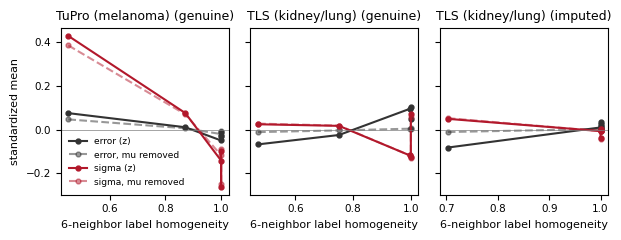


CAPTION: Prediction error and predicted uncertainty against the spatial homogeneity of a spot neighborhood, by quintile. Low homogeneity marks a region boundary, where a spot pools two transcriptional programmes. Dashed curves are the same quantities after the monotone effect of the predicted mean has been removed within slide.


In [25]:
if prof:
    fig, axes = plt.subplots(1, len(prof), figsize=(6.3, 2.5), squeeze=False, sharey=True)
    for ax, (key, p) in zip(axes[0], prof.items()):
        hc = [c for c in p.columns if c.startswith('homog_')][0]
        ax.plot(p[hc], p['err_z'], 'o-', ms=3.5, color='#333333', label='error (z)')
        ax.plot(p[hc], p['err_resid'], 'o--', ms=3.5, color='#333333', alpha=0.5,
                label='error, mu removed')
        ax.plot(p[hc], p['sigma_z'], 'o-', ms=3.5, color='#B2182B', label='sigma (z)')
        ax.plot(p[hc], p['sigma_resid'], 'o--', ms=3.5, color='#B2182B', alpha=0.5,
                label='sigma, mu removed')
        ax.axhline(0, color='gray', lw=0.5)
        ax.set_xlabel('6-neighbor label homogeneity', fontsize=8)
        ax.tick_params(labelsize=7.5)
        ax.set_title(f'{DATASET_LABELS.get(key[0], key[0])} ({key[1]})', fontsize=9)
    axes[0][0].set_ylabel('standardized mean', fontsize=8)
    axes[0][0].legend(fontsize=6.5, frameon=False)
    fig.tight_layout()
    save_fig(fig, 'bio_spot_mixture')
    plt.show()
    print('\nCAPTION: Prediction error and predicted uncertainty against the spatial homogeneity of'
          ' a spot neighborhood, by quintile. Low homogeneity marks a region boundary, where a'
          ' spot pools two transcriptional programmes. Dashed curves are the same quantities after'
          ' the monotone effect of the predicted mean has been removed within slide.')

## 7. Recap

Read in this order to write the section:

1. **Section 2** gives `share_gene(log sigma) - share_gene(log|error|)`. That is the central
   number: it quantifies the redundancy in one quantity, with the per-donor points.
2. **Section 3** gives the gene names, the qualitative deliverable, plus the confound to declare
   (sigma follows expression).
3. **Section 4** says whether the ranking is a property of the gene or of the cohort. Never read
   without the reliability ceiling.
4. **Section 5**, the `*_resid` rows: the only confirmatory test in the section.
5. **Section 6**: if the error rises at boundaries and the residual sigma does not follow, that is
   the strongest available deflation. If sigma does follow, it is the one place where the
   uncertainty is informative, and it is biologically interpretable.

**Standing prohibitions.** No count versus Gaussian ranking; no `*_raw` model; never pooled across
cohorts; `sigma` never multiplied by `(1+mu)`.

In [26]:
print('=== NUMBERS TO REPORT ===\n')
if 'gap' in dir():
    print('1. Gene-share gap (sigma minus error), mean over donors:')
    print(gap.groupby(level=0)['gap'].agg(['mean', 'std', 'size']).round(4).to_string())
if 'rr' in dir() and not rr.empty:
    print('\n2. Tissue contrast AFTER controlling for mu (confirmatory):')
    print(rr[rr['quantity'].str.endswith('resid')].round(4).to_string(index=False))
if 'mx' in dir() and not mx.empty:
    print('\n3. Boundary spots against homogeneous interior:')
    print(mx.round(4).to_string(index=False))
print(f'\nFigures written to {FIG_DIR.relative_to(PROJ)}')


=== NUMBERS TO REPORT ===

1. Gene-share gap (sigma minus error), mean over donors:
               mean     std  size
dataset                          
10x_TuPro    0.1566  0.0231     7
LUNG_CANCER  0.1449  0.0244     8
TLS          0.1624  0.0628     6

2. Tissue contrast AFTER controlling for mu (confirmatory):
  dataset  labels    quantity  n_donors  mean_delta  ci_low  ci_high positive_donors  sign_p
10x_TuPro genuine sigma_resid         7      1.2478  0.8683   1.6274             7/7  0.0156
10x_TuPro genuine   err_resid         7      0.1323  0.0551   0.2095             7/7  0.0156
      TLS genuine sigma_resid         6      0.4758 -0.0617   1.0133             5/6  0.2188
      TLS genuine   err_resid         6     -0.0665 -0.1041  -0.0288             0/6  0.0312
      TLS imputed sigma_resid         6      0.3342 -0.1354   0.8038             5/6  0.2188
      TLS imputed   err_resid         6     -0.0493 -0.0744  -0.0241             0/6  0.0312

3. Boundary spots against homogen